# **Práctica 5**

## **Resumen**
En este trabajo se aplicaron los conceptos fundamentales del análisis frecuencial de señales. En el numeral 4.1 se generó una señal compuesta por la suma de tres componentes sinusoidales de 40, 80 y 160 Hz. Para representarla adecuadamente se determinó la frecuencia de muestreo mínima según el teorema de Nyquist-Shannon, que exige una frecuencia mayor a dos veces la frecuencia máxima de la señal, es decir, mayor a 320 Hz. Se escogió una frecuencia de muestreo de 1000 Hz, bastante superior a ese mínimo, para reflejar bien la señal.

En el numeral 4.2 se calculó la transformada de Fourier de la señal, trabajando con 10 periodos, y se graficó su espectro de frecuencia para verificar que las componentes de 40, 80 y 160 Hz estuvieran presentes. Como el espectro de una señal real es simétrico, es decir, la segunda mitad es un reflejo de la primera, también se graficó únicamente la primera mitad, que llega hasta la frecuencia de Nyquist.

En el numeral 4.3 se calculó la transformada inversa de Fourier de la señal mediante la función ifft. Al graficarla superpuesta con la señal original en el dominio del tiempo, se comprobó que ambas son idénticas, lo que confirma que la transformada de Fourier no pierde información.

En el numeral 4.4 se analizó un código que aplica un filtro pasa banda en el dominio de la frecuencia. Este crea un segundo vector de ceros del mismo tamaño que el espectro de la señal y copia en él únicamente los coeficientes de los índices k asociados a la frecuencia que se desea conservar. Al aplicar la transformada inversa se obtiene solo esa componente. Este procedimiento se repitió para cada una de las tres frecuencias dadas al inicio, extrayendo así cada componente por separado.

En el numeral 4.5 se analizó la señal de ECG contenida en el archivo senecg.mat. Primero se extrajo la señal y se le calculó el periodograma de Welch, obteniendo la frecuencia y la potencia asociadas, para lo cual se empleó una ventana tipo Hanning de 500 muestras de ancho y un solapamiento del 50 %. Este análisis permitió identificar la frecuencia de mayor potencia y más dominante en la señal, que correspondió a 60 Hz, es decir, a la interferencia de la red eléctrica. Se calculó entonces el índice k asociado a esa frecuencia y se filtró la señal con el método anterior, anulando esos coeficientes y aplicando la transformada inversa. Finalmente, se volvió a calcular el periodograma para corroborar que la componente de 60 Hz había desaparecido. Se realizaron cuatro gráficas que muestran la señal en el dominio del tiempo y de la frecuencia, con y sin ruido.

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio                  
from scipy.signal import welch as pwelch

**4.1)** Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 
80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, 
y utilice la frecuencia de muestreo necesaria para representarla apropiadamente.

- **Respuesta**

Frecuencia máxima de la señal (f_max): 160 Hz
Frecuencia de muestreo mínima teórica (Nyquist): 320 Hz


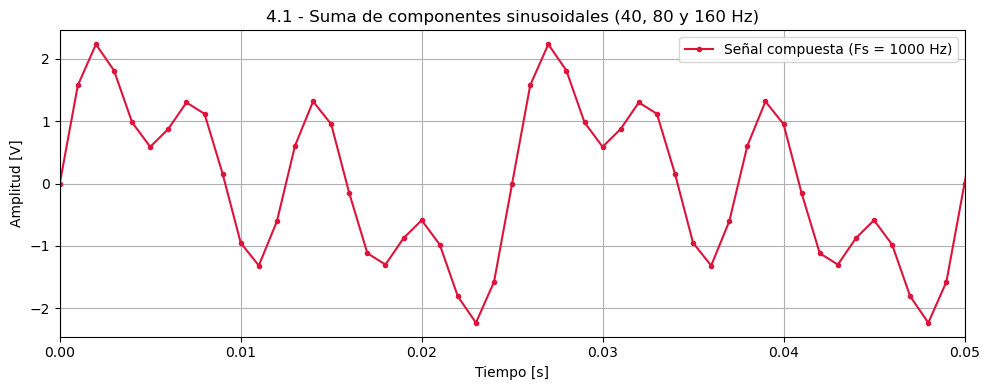

In [30]:
# Se definen las frecuencias de las tres componentes sinusoidales a usar en Hz
f1 = 40     
f2 = 80    
f3 = 160   #Frecuencia maxima de la señal 

#Se calcula la frecuencia de muestreo mínima según el Teorema de Nyquist-Shannon
# es el doble de la frecuencia máxima presente en la señal
Fs_min = 2 * f3
print(f"Frecuencia máxima de la señal (f_max): {f3} Hz")
print(f"Frecuencia de muestreo mínima teórica (Nyquist): {Fs_min} Hz")

# Sin embargo, se escoge una frecuencia de muestreo mayor, para que la señal 
#pueda verse bien representada en todas sus frecuencias

Fs = 1000         # Frecuencia de muestreo 
Ts = 1 / Fs       # Periodo de muestreo (intervalo de tiempo entre muestras, en segundos)

# Se defin el vector de tiempo
# Para esto se haya el periodo fundamental y este periodo existe si 
# sus frecuencias pueden expresarse como múltiplos enteros de una misma frecuencia fundamental.
# Por lo tanto, la frecuencia fundamental es el minimo comun divisor de 40, 80, 160. 
# la frecuencia fundamental es 40 y el periodo  fundamental Tp = 1/fp 
Tp = 1 / f1
t = np.arange(0, 10 * Tp, Ts)   # Genera 250 muestras equidistantes desde t = 0 hasta t = 0.249 s

# Se construye cada componente sinusoidal y suma total
x_40 = np.sin(2 * np.pi * f1 * t)    
x_80 = np.sin(2 * np.pi * f2 * t)    
x_160 = np.sin(2 * np.pi * f3 * t)   
signal = x_40 + x_80 + x_160         # Señal compuesta en el dominio del tiempo

# Se ggrafica la señal compuesta (se muestran los primeros 2 periodos para apreciar su forma)
plt.figure(figsize=(10, 4))
plt.plot(t, signal, label=f"Señal compuesta (Fs = {Fs} Hz)", color='crimson', marker='o', markersize=3)
plt.title("4.1 - Suma de componentes sinusoidales (40, 80 y 160 Hz)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud [V]")
plt.xlim(0, 2 * Tp)   # Zoom en 2 periodos para visualizar la morfología de la onda
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

**4.2)** Calcule  la  transformada  de  Fourier  de  la  señal  y  grafique  el  espectro  de  frecuencia. 
Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos 
de la señal)

- **Respuesta**

250
125


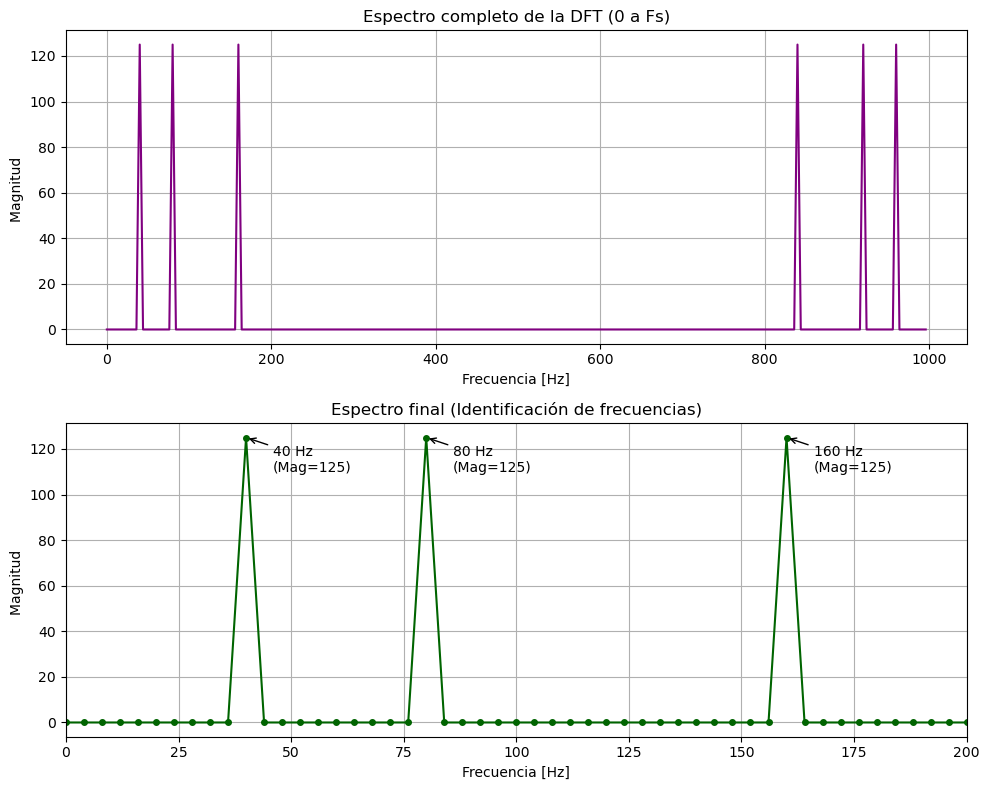

In [31]:
# Como en el punto anterior la señal se realizo con un periodo de 10 ahora iniciamos:
# Calculando la transformada de Fourier sobre los 10 periodos de la señal original ('signal') y
# y guardamos el resultado para conservar la señal del tiempo
signal_fft = np.fft.fft(signal)


N = len(signal_fft)                 # Número total de muestras 
print (N)
F = np.arange(0, N) * Fs / N   # para extraer las frecuencias en tiempo continuo: frecuencia F = (k * Fs) / N 


# Como la señal es real, la segunda mitad del espectro es un espejo de la primera.
# Nos quedamos solo con la primera mitad para analizarla con claridad.
N_mitad = int(np.ceil(N / 2))  # Punto medio del arreglo
print(N_mitad)
F_mitad = F[0:N_mitad]         # Frecuencias desde 0 Hz hasta Fs/2
signal_fft_mitad = signal_fft[0:N_mitad]     # Valores de la FFT correspondientes a esa mitad


# Graficamos la componente frecuencial de la señal 
plt.figure(figsize=(10, 8))

# Primero graficamos el espectro completo
plt.subplot(2, 1, 1)
plt.plot(F, np.abs(signal_fft), color='purple')       
plt.title("Espectro completo de la DFT (0 a Fs)")      
plt.xlabel("Frecuencia [Hz]")                          
plt.ylabel("Magnitud ")                          
plt.grid(True)                                        

# Luego graficamos el espectro hasta Nyquist con zoom 
plt.subplot(2, 1, 2)
plt.plot(F_mitad, np.abs(signal_fft_mitad), color='darkgreen', marker='o', markersize=4)
plt.title("Espectro final (Identificación de frecuencias)")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud ")
plt.xlim(0, 200)                                       
plt.grid(True)

# Recorremos las 3 frecuencias objetivo para señalar cada pico con una flecha
for freq_objetivo in [40, 80, 160]:
    idx = int(freq_objetivo * N / Fs)   # Calculamos en qué índice del arreglo cae esa frecuencia
    mag = np.abs(signal_fft_mitad[idx])          # Obtenemos la altura (magnitud) del pico en ese índice

    # Dibujamos la flecha y el texto sobre la gráfica activa (la #2)
    plt.annotate(
        f"{freq_objetivo} Hz\n(Mag={mag:.0f})",         
        xy=(freq_objetivo, mag),                        
        xytext=(freq_objetivo + 6, mag - 15),           
        arrowprops=dict(arrowstyle="->", color="black") 
    )

plt.tight_layout()
plt.show()

**4.3)** Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. 
Aplíquelo a la señal anterior.

- **Respuesta**

Error máximo de reconstrucción entre signal e ifft(fft(signal)): 1.11e-15


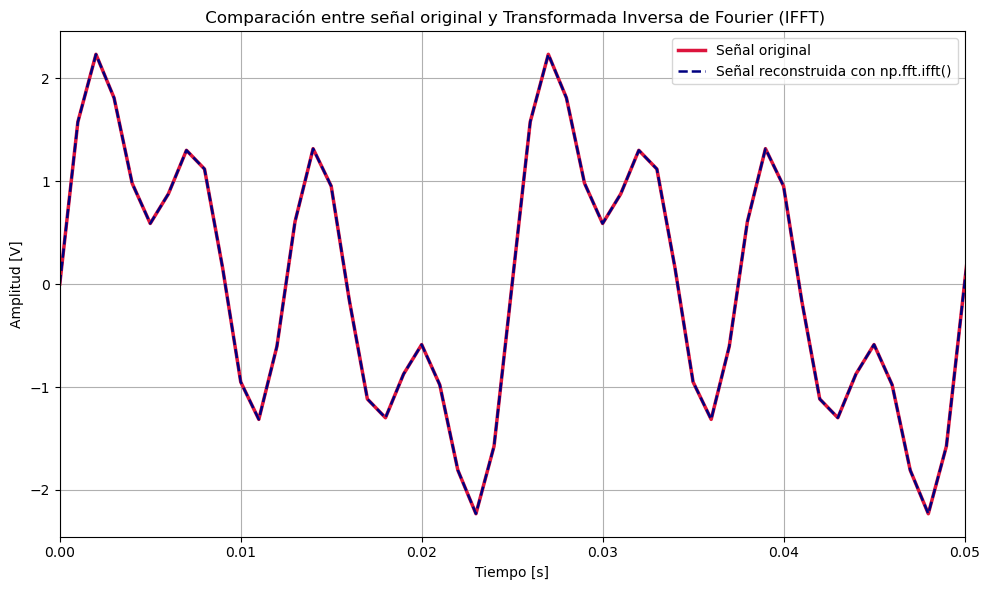

In [ ]:
# La función en NumPy  para calcular la Transformada Discreta Inversa de Fourier
# es `np.fft.ifft()`. Esta permite reconstruir la señal en el dominio
# del tiempo a partir de sus coeficientes complejos en el dominio de la frecuencia. 

# Aplicamos la IFFT al espectro 'signal_fft' calculado en el numeral anterior
signal_reconstruida_compleja = np.fft.ifft(signal_fft)

# Luego extraemos la parte real con `np.real()` porque, debido a errores de redondeo de punto
# flotante (~1e-16j), la salida de `ifft` es de tipo complejo aunque la parte imaginaria sea nula.
signal_reconstruida = np.real(signal_reconstruida_compleja)

# Finalmente, verificamos numéricamente que el error máximo respecto a la señal original sea prácticamente cero
# Esto para corroborar que la señal construida a partir de este metodo si este correcta
error_maximo = np.max(np.abs(signal - signal_reconstruida))
print(f"Error máximo de reconstrucción entre signal e ifft(fft(signal)): {error_maximo:.2e}")

# Graficamos la señal original vs. la reconstruida mediante IFFT, para corroborar que se haya reconstruido fielmente
plt.figure(figsize=(10, 6))
plt.plot(t, signal, label="Señal original", color='crimson', linewidth=2.5)
plt.plot(t, signal_reconstruida, '--', label="Señal reconstruida con np.fft.ifft()", color='navy', linewidth=1.8)
plt.title(" Comparación entre señal original y Transformada Inversa de Fourier (IFFT)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud [V]")
plt.xlim(0, 2 * Tp)   # Mostramos 2 periodos para comprobar la superposición exacta
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

- Se analiza que hay una alta similitud entre las señales, lo cual demuestra la buena reproducibilidad de la señal mediante el método de la trasnformada rapida de fourier

**4.4)** ¿Se Podría decir que las siguientes líneas aplican un filtro? ¿Por qué? 

F1 = np.fft.fft(x);

F2 = np.zeros((len(F1))); 

F2[9:13] = F1[9:13]; 

xr = np.fft.ifft(F2); 

fig = plt.figure() 

ax = fig.add_subplot(111) 

ax.plot(t, np.real(xr)) 

Introducción al análisis frecuencial de señales Bioseñales y sistemas 

ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)'); 

plt.show() 

Extraiga de manera similar cada una de las componentes de la señal.

- **Respuesta**

**Sí, las líneas de código aplican un filtro pasa-banda ideal en el dominio de la frecuencia.** 

Esto ocurre porque hay dos señales, una real que contiene todo el espectro de la frecuencia (F1), y la otra tiene el mismo tamaño, pero es solo un arreglo de ceros (F2). Seguidamente, en la linea 3 ocurre el filtrado de la señal. Aqui se reescriben únicamente las componentes de frecuencia ubicadas en los índices 9, 10, 11 y 12 desde F1 hacia F2. Todo lo demás queda en cero. Con esto se aisla una banda específica de frecuencias y se elimina ruido o componentes no deseadas de la señal original.
Todo esto se realiza antes de regresar al dominio del tiempo mediante  la función `ifft()`, en la linea 4.
Finalmente, se grafica la señal en el domino de tiempo, sin el ruido o componentes frecuenciales no deseadas.

40 Hz Índice positivo k = 10
80 Hz Índice positivo k = 20
160 Hz Índice positivo k = 40


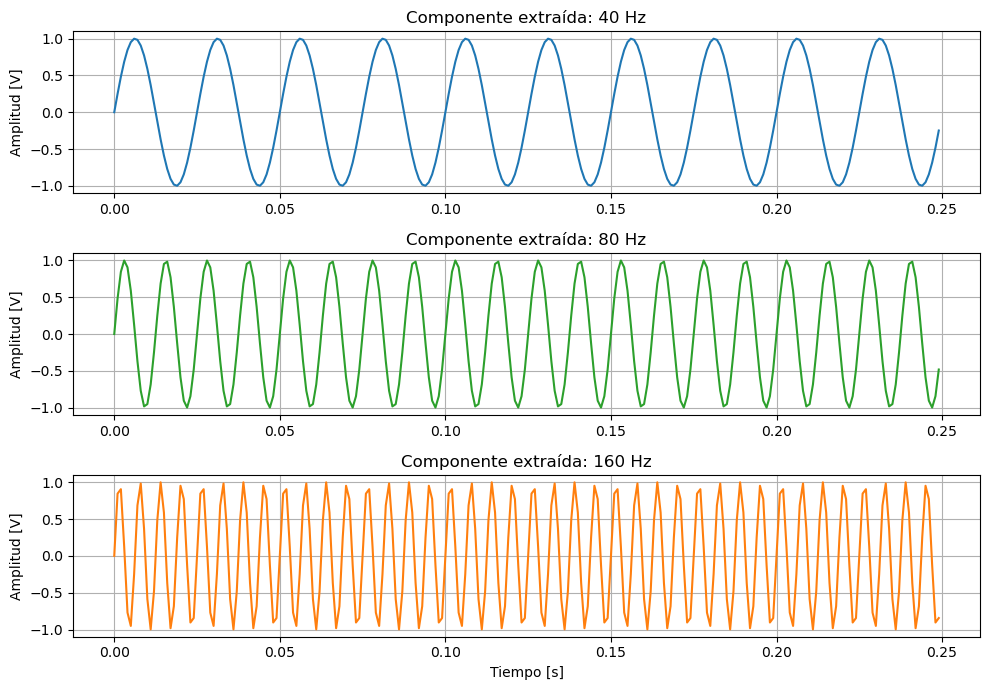

In [51]:
#Ahora vamos a extraer de manera similar cada una de las componentes de la señal 


# Creamos un arreglo lleno de ceros del mismo tamaño que signal_fft, 
# la cual, es la señal inicial con la transformada de fourier aplicada.
# Usamos dtype=complex para que Python permita guardar números complejos (magnitud y fase)
# sin borrar la parte imaginaria ni mostrar errores.
F_40 = np.zeros(len(signal_fft), dtype=complex)

# calculamos el indice donde esta la frecuencia que queremos conservar
delta_f = Fs / N  # Paso de frecuencia entre índices 
k = int(round(40 / delta_f))
print(f"{40} Hz Índice positivo k = {k}")
k = int(round(80 / delta_f))
print(f"{80} Hz Índice positivo k = {k}")
k = int(round(160 / delta_f))
print(f"{160} Hz Índice positivo k = {k}")

# Copiamos únicamente los índices 9, 10, 11 y 12 (donde está el pico de 40 Hz).
# Todo el resto del espectro queda en cero.
F_40[9:13] = signal_fft[9:13]
F_40[N-12:N-8] = signal_fft[N-12:N-8]
# Aplicamos la Transformada Inversa de Fourier (IFFT) para volver al dominio del tiempo.
# Como solo copiamos el lado positivo del espectro, la amplitud sale a la mitad (0.5 V).
xr_40 = np.fft.ifft(F_40)
    

# Ahora extraemos unicamente la componente de 80 Hz
F_80 = np.zeros(N, dtype=complex)          
F_80[19:23] = signal_fft[19:23]                    # Conservamos lado positivo alrededor de k = 20
F_80[N-22:N-18] = signal_fft[N-22:N-18]
xr_80 = np.real(np.fft.ifft(F_80))         # Regresamos al domino del tiempo 


# Finalmente extraemos la componente de 160 Hz
F_160 = np.zeros(N, dtype=complex)       
F_160[39:43] = signal_fft[39:43]                   # Conservamos lado positivo alrededor de k = 40
F_160[N-42:N-38] = signal_fft[N-42:N-38]
xr_160 = np.real(np.fft.ifft(F_160))       # Regresamos al dominio del tiempo


#Graficamos cada una de las señales

plt.figure(figsize=(10, 7))                
plt.subplot(3, 1, 1)                       
plt.plot(t, xr_40, color='tab:blue')
plt.title("Componente extraída: 40 Hz")
plt.ylabel("Amplitud [V]")
#plt.xlim(0, 2 * Tp)                        # Zoom a 0.05 s (muestra 2 ciclos completos de 40 Hz)
plt.grid(True)

# --- Subgráfica 2 (Centro): 80 Hz ---
plt.subplot(3, 1, 2)                       
plt.plot(t, xr_80, color='tab:green')
plt.title("Componente extraída: 80 Hz")
plt.ylabel("Amplitud [V]")
#plt.xlim(0, 2 * Tp)                        # Zoom a 0.05 s (muestra 4 ciclos completos de 80 Hz)
plt.grid(True)

# --- Subgráfica 3 (Abajo): 160 Hz ---
plt.subplot(3, 1, 3)                       
plt.plot(t, xr_160, color='tab:orange')
plt.title("Componente extraída: 160 Hz")
plt.xlabel("Tiempo [s]")                   
plt.ylabel("Amplitud [V]")
#plt.xlim(0, 2 * Tp)                        # Zoom a 0.05 s (muestra 8 ciclos completos de 160 Hz)
plt.grid(True)

plt.tight_layout()                         
plt.show()                                 

**4.5)** Realice un análisis en frecuencia de la señal usando periodogramas 
de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que 
se  mostró  antes  y  compruebe  que  lo  haya  realizado,  calcule  la  transformada  inversa  de 
Fourier de la señal filtrada y compruebe con el periodograma.

- **Respuesta**

Frecuencia dominante detectada en el periodograma original: 60.0 Hz
60 Hz Índice positivo k = 300
Frecuencia dominante detectada en el periodograma original: 1.0 Hz


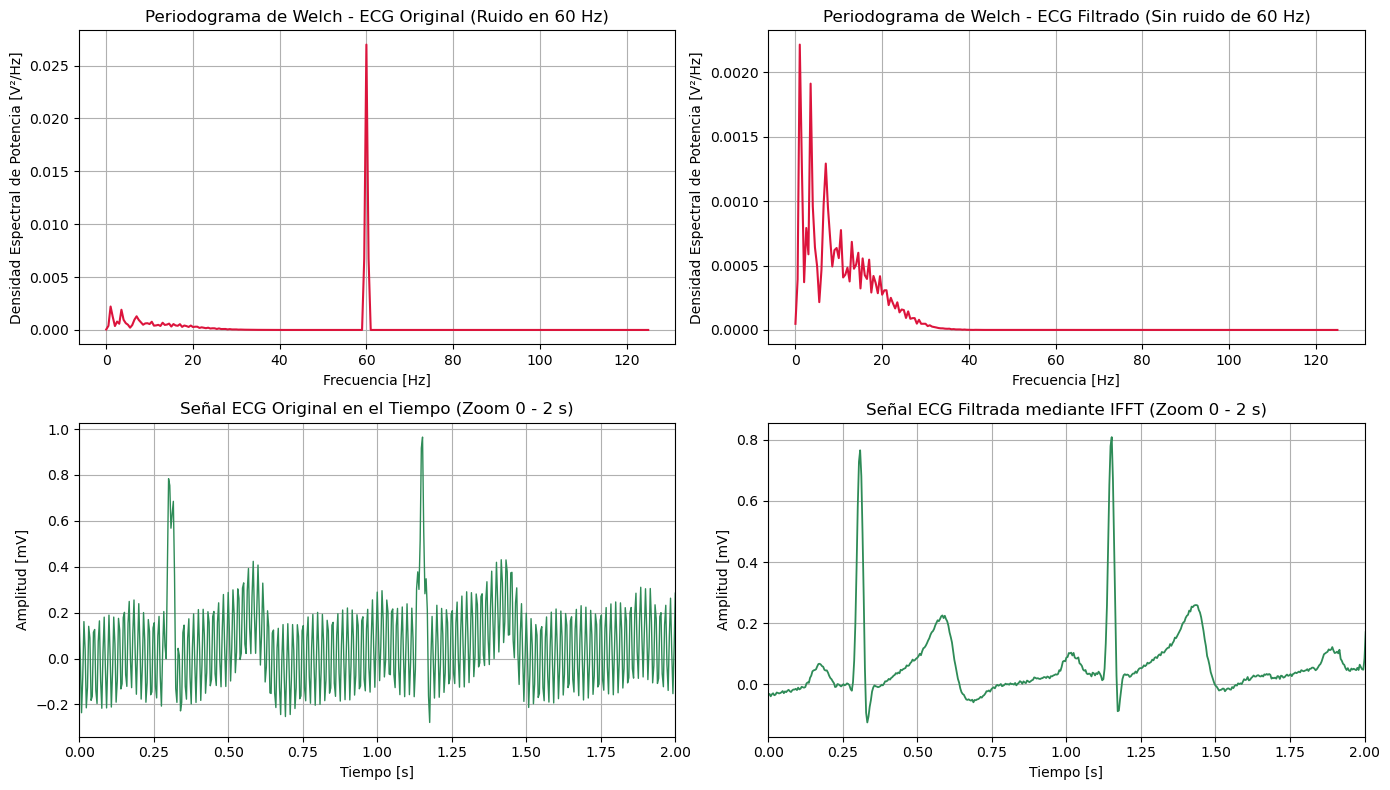

In [52]:
#Primero caragamos los datos que contienen la señal ECG
datos_ecg = sio.loadmat('senecg.mat')  
ecg = datos_ecg['ECG'].squeeze()    # Extrae la señal y la convierte de matriz a vector 1D   

fs_ecg = 250                           # Según el enunciado, la frecuencia de muestreo de la señal ECG 
N_ecg = len(ecg)                       # Total de muestras, que seria la longitud del vector
t_ecg = np.arange(N_ecg) / fs_ecg      # Vector de tiempo que tenga la extencion de la señal 



# El método de Welch divide la señal en ventanas suavizadas para ver con claridad
# en qué frecuencias se concentra la potencia o energía de la señal.
nperseg = 500                          # Tomamos un tamaño de cada ventanade 500 muestras
noverlap = int(nperseg / 2)            # Solapamiento del 50% entre ventanas (250 muestras)

# Calculamos las frecuencias (f_welch) y la potencia en cada frecuencia (Pxx_orig)
f_welch, Pxx_orig = pwelch(ecg, fs=fs_ecg, window='hann', nperseg=nperseg, noverlap=noverlap)

# Buscamos automáticamente en qué frecuencia está el pico más alto de potencia
indice_max = np.argmax(Pxx_orig)       # Posición del valor máximo en Pxx_orig
freq_ruido = f_welch[indice_max]       # Frecuencia correspondiente a ese pico
print(f"Frecuencia dominante detectada en el periodograma original: {freq_ruido} Hz")


#Luego de saber que el ruido tiene una frecuencia de 60 Hz, lo eliminamos usando el metodo 
# anterior, pero ahora en forma de rechaza banda

#Realizamos la transformada de Fourier a la señal a filtrar
F_ecg = np.fft.fft(ecg)                # Pasamos la señal ECG al dominio de la frecuencia
F_ecg_filtrada = F_ecg.copy()          # Hacemos una copia para no dañar el espectro original

#Calculamos el indice asociado a la frecuencia de 60Hz que deseamos eliminar
paso = fs_ecg / N_ecg  # Paso de frecuencia entre índices 
k = int(round(60 / paso))
print(f"{60} Hz Índice positivo k = {k}")

# Aplicamos el filtro rechaza banda y ponemos en cero el pico de 60 Hz y sus vecinos (59.8, 60.0 y 60.2 Hz)
F_ecg_filtrada[299:302] = 0                          # Borra el pico en el lado positivo (alrededor de k = 300)
F_ecg_filtrada[N_ecg - 301 : N_ecg - 298] = 0        # Borra su espejo en el lado negativo (alrededor de 950)



# Regresamos la señal filtrada al dominio del tiempo usando la Transformada Inversa de Fourier (IFFT)
ecg_filtrada = np.real(np.fft.ifft(F_ecg_filtrada))

# Calculamos un nuevo periodograma de Welch sobre la señal ya filtrada
# para comprobar que el pico de 60 Hz desapareció por completo
f_welch_filt, Pxx_filt = pwelch(ecg_filtrada, fs=fs_ecg, window='hann', nperseg=nperseg, noverlap=noverlap)

indice_max = np.argmax(Pxx_filt)       # Posición del valor máximo en Pxx_orig
freq_ruido2 = f_welch[indice_max]       # Frecuencia correspondiente a ese pico
print(f"Frecuencia dominante detectada en el periodograma original: {freq_ruido2} Hz")


# Graficamos las señales para comprobar

plt.figure(figsize=(14, 8))

# Graficcamos primero el espectro original con ruido, en el dominio de la frecuencia
plt.subplot(2, 2, 1)                   
plt.plot(f_welch, Pxx_orig, color='crimson')
plt.title("Periodograma de Welch - ECG Original (Ruido en 60 Hz)")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad Espectral de Potencia [V²/Hz]")
plt.grid(True)

# Graficamos de segundo espectro limpio sin ruido en el dominio de la frecuencia
plt.subplot(2, 2, 2)                 
plt.plot(f_welch_filt, Pxx_filt, color='crimson')
plt.title("Periodograma de Welch - ECG Filtrado (Sin ruido de 60 Hz)")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad Espectral de Potencia [V²/Hz]")
plt.grid(True)

# Graficamos de tercero la Señal ECG en el tiempo con ruido 
plt.subplot(2, 2, 3)                   
plt.plot(t_ecg, ecg, color='seagreen', linewidth=1)
plt.title("Señal ECG Original en el Tiempo (Zoom 0 - 2 s)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud [mV]")
plt.xlim(0, 2.0)                       # Zoom de 0 a 2 segundos para notar la vibración del ruido
plt.grid(True)

# Graficamos de cuarto la Señal ECG en el tiempo ya limpia
plt.subplot(2, 2, 4)                   
plt.plot(t_ecg, ecg_filtrada, color='seagreen', linewidth=1.3)
plt.title("Señal ECG Filtrada mediante IFFT (Zoom 0 - 2 s)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud [mV]")
plt.xlim(0, 2.0)                       # Mismo zoom de 0 a 2 segundos para comparar lado a lado
plt.grid(True)


plt.tight_layout()
plt.show()

**Justificación de parámetros de Welch y diagnóstico del ruido:**

- **Ancho de ventana:** Como la señal tiene $1250$ muestras a $f_s = 250\text{ Hz}$, su duración total es de $5\text{ s}$. Escoger una ventana de $500$ muestras equivale a analizar bloques de $2\text{ s}$, logrando un equilibrio ideal: brinda una precisión de $\Delta f = 250 / 500 = 0.5\text{ Hz}$.  Esta resolución frecuencial de 0,5 Hz, es suficiente para identificar las frecuencias presentes en el ECG y detectar posibles interferencias. Además, al tener 1250 muestras en total, se pueden analizar varios segmentos y promediarlos para obtener un espectro más estable.
- **Solapamiento:** Para evitar fugas espectrales (spectral leakage), la ventana Hanning atenúa hacia cero los extremos de cada bloque de $2\text{ s}$. Al superponer las ventanas a la mitad ($50\%$), se recuperan los datos que perdieron amplitud en esos bordes, obteniendo una estimación espectral más estable y confiable sin repetir información en exceso.
- **Diagnóstico:** El periodograma de Welch revela un pico dominante y muy estrecho exactamente en $60\text{ Hz}$. Esto en la captacion de señales ECG, es causado por la interferencia de la red eléctrica. Dado que la actividad fisiológica del ECG se concentra entre $0.5\text{ Hz}$ y $35\text{ Hz}$, sí es necesario eliminar esta componente mediante un filtro rechaza-banda (notch) en la FFT para limpiar el trazo sin deformar las ondas del corazón.

**4.6)** Realice un análisis de frecuencia a través del periodograma de welch de una señal de ECG 
de un paciente Sano y otra de un sujeto con una arritmia en la que hayan identificado que 
presentaba diferencias, si no encontró diferencias, elija un par al azar. Realice un análisis 
comparativo de las señales según lo que le indiquen los periodogramas.

- **Respuesta** 

### Escoger datos de los que se tienen del primer trabajo e identificar diferencias con el digrama de welch

**4.7)** Conclusiones y referencias (10%)

### **Conclusiones**

- Al analizar la señal compuesta por $40\text{ Hz}$, $80\text{ Hz}$ y $160\text{ Hz}$, se comprobó que muestrear justo en el límite teórico de Nyquist ($320\text{ Hz}$) hace que la componente de $160\text{ Hz}$ desaparezca al coincidir las muestras con sus cruces por cero, mientras que aumentar la frecuencia de muestreo a $1000\text{ Hz}$ ($250$ muestras) permite capturar la forma real de la señal y visualizar sin pérdidas los tres picos en el espectro.

- El uso combinado de la Transformada Rápida de Fourier (fft) y su inversa (ifft) permite separar las frecuencias de una señal compuesta para aislarlas o eliminarlas individualmente; sin embargo, al filtrar señales reales es indispensable conservar tanto los índices positivos ($k = 10, 20, 40$) como sus espejos en el lado negativo ($N - k = 240, 230, 210$), ya que tomar únicamente la mitad positiva reduce la amplitud reconstruida a la mitad ($0.5\text{ V}$ en lugar de $1\text{ V}$).

- La resolución frecuencial ($\Delta f = F_s / N$) demostró ser un parámetro clave para ubicar con exactitud cada componente dentro del espectro, ya que permitió determinar que cada índice avanzaba cada $4\text{ Hz}$ en la señal sintética y cada $0.2\text{ Hz}$ en la señal ECG, facilitando diseñar filtros muy precisos que eliminan solo la frecuencia deseada sin dañar las bandas vecinas.

- En el estudio de la señal electrocardiográfica senecg.mat ($5\text{ s}$ a $250\text{ Hz}$), el periodograma de Welch con ventana Hanning de $2\text{ s}$ ($500$ muestras) y solapamiento del $50\%$ suavizó las variaciones aleatorias del espectro y dejó en evidencia un pico dominante de interferencia eléctrica en $60\text{ Hz}$, el cual se eliminó mediante la ifft ($k = 300$ y $950$) dejando limpio el trazo en el tiempo y conservando intactas las ondas P, QRS y T.

- OTRAAA



### *Referencias**

- [1]	Mathworks.com. Consultado: el 22 de noviembre de 2026. [En línea]. Disponible en: https://la.mathworks.com/help/matlab/ref/ifft.html

* **[2]** J. G. Proakis, D. G. Manolakis, *"Digital Signal Processing: Principles, Algorithms, and Applications"*, 4th ed., págs. 75–77, Ed. Prentice Hall, 2007.

* **[3]** P. Welch, *"The use of fast Fourier transform for the estimation of power spectra: A method based on time averaging over short, modified periodograms"*, IEEE Transactions on Audio and Electroacoustics, vol. 15, no. 2, págs. 70–73, 1967.

* **[4]** Documentación oficial de SciPy (`scipy.signal.welch` y `scipy.fft`), disponible en: https://docs.scipy.org/doc/scipy/reference/signal.html